# Random Forest Comparison

In [ ]:
# imports

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import cross_val_score
# This code imports the required libraries for data handling,
 #visualization, Random Forest modelling, model evaluation, and cross-validation.”

In [ ]:
# paths

ROOT = Path.cwd()

while not (ROOT / "results" / "outputs").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent

ORIGINAL_DIR = ROOT / "results" / "outputs" / "original"
NEW_DIR = ROOT / "results" / "outputs" / "new"

RESULT_DIR = ROOT / "results" / "model_results" / "random_forest"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
#Project path setup
#This code finds the project root directory and defines the paths for the original
 #dataset, new dataset, and Random Forest results folder.”

Project root: /home/kashmira/git/crop-soil-fertilizer


In [ ]:
# load data

original_train = pd.read_csv(ORIGINAL_DIR / "train_processed.csv")
original_test = pd.read_csv(ORIGINAL_DIR / "test_processed.csv")

new_train = pd.read_csv(NEW_DIR / "train_processed.csv")
new_test = pd.read_csv(NEW_DIR / "test_processed.csv")

original_mapping = pd.read_csv(ORIGINAL_DIR / "label_mapping.csv")
new_mapping = pd.read_csv(NEW_DIR / "label_mapping.csv")

print("Original train:", original_train.shape)
print("Original test:", original_test.shape)

print("\nNew train:", new_train.shape)
print("New test:", new_test.shape)
#Create result folder
# This code loads the original and new training and testing datasets, along with 
#their label mappings, and then displays their sizes using the shape function.”


Original train: (6400, 24)
Original test: (1600, 24)

New train: (3610, 36)
New test: (903, 36)


In [ ]:
# prepare data

target = "Target_Label"

X_train_original = original_train.drop(columns=[target])
y_train_original = original_train[target]

X_test_original = original_test.drop(columns=[target])
y_test_original = original_test[target]

X_train_new = new_train.drop(columns=[target])
y_train_new = new_train[target]

X_test_new = new_test.drop(columns=[target])
y_test_new = new_test[target]
#Load datasets
# This code separates the dataset into X, which contains the input features, and y, 
#which contains the target fertilizer labels, for both training and testing data.”


In [ ]:
# evaluation

def evaluate_random_forest(
    name,
    X_train,
    y_train,
    X_test,
    y_test,
):
    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_train, y_train)
    baseline_pred = baseline.predict(X_test)

    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    cv_scores = cross_val_score(
        RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1,
        ),
        X_train,
        y_train,
        cv=5,
        scoring="accuracy",
        n_jobs=-1,
    )

    result = {
        "Dataset": name,
        "Majority_Baseline": accuracy_score(y_test, baseline_pred),
        "Train_Accuracy": accuracy_score(y_train, train_pred),
        "Test_Accuracy": accuracy_score(y_test, test_pred),
        "Precision_Weighted": precision_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "Recall_Weighted": recall_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "F1_Weighted": f1_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "F1_Macro": f1_score(
            y_test,
            test_pred,
            average="macro",
            zero_division=0,
        ),
        "CV_Accuracy_Mean": cv_scores.mean(),
        "CV_Accuracy_Std": cv_scores.std(),
        "Trees": model.n_estimators,
    }

    return model, test_pred, result
    #This function trains the Random Forest model, makes predictions, evaluates its performance 
   # using different metrics and 5-fold cross-validation, and returns the model and results.”


In [ ]:
# train both datasets

original_model, original_pred, original_result = evaluate_random_forest(
    "Original",
    X_train_original,
    y_train_original,
    X_test_original,
    y_test_original,
)

new_model, new_pred, new_result = evaluate_random_forest(
    "New",
    X_train_new,
    y_train_new,
    X_test_new,
    y_test_new,
)

results = pd.DataFrame([
    original_result,
    new_result,
])

display(results.round(4))
#Separate X and y
→ X = input features
→ y = target fertilizer class that we want to predict.
#This code evaluates the Random Forest model on both the Original and
#New datasets, stores their results, and displays them together for comparison.”


,Dataset,Majority_Baseline,Train_Accuracy,Test_Accuracy,Precision_Weighted,Recall_Weighted,F1_Weighted,F1_Macro,CV_Accuracy_Mean,CV_Accuracy_Std,Trees
0,Original,0.1488,1.0000,0.1356,0.1354,0.1356,0.1353,0.1353,0.1436,0.0041,300
1,New,0.3023,0.9994,0.8372,0.8408,0.8372,0.8375,0.7687,0.8050,0.0110,300


In [ ]:
# save results

results.to_csv(
    RESULT_DIR / "random_forest_comparison.csv",
    index=False,
)

print("Saved:", RESULT_DIR / "random_forest_comparison.csv")
#Create Dummy Classifier
→ Creates a simple baseline model to compare with the Random Forest model.

#This code saves the Random Forest comparison results
# as a CSV file in the specified results folder.”

Saved: /home/kashmira/git/crop-soil-fertilizer/results/model_results/random_forest/random_forest_comparison.csv


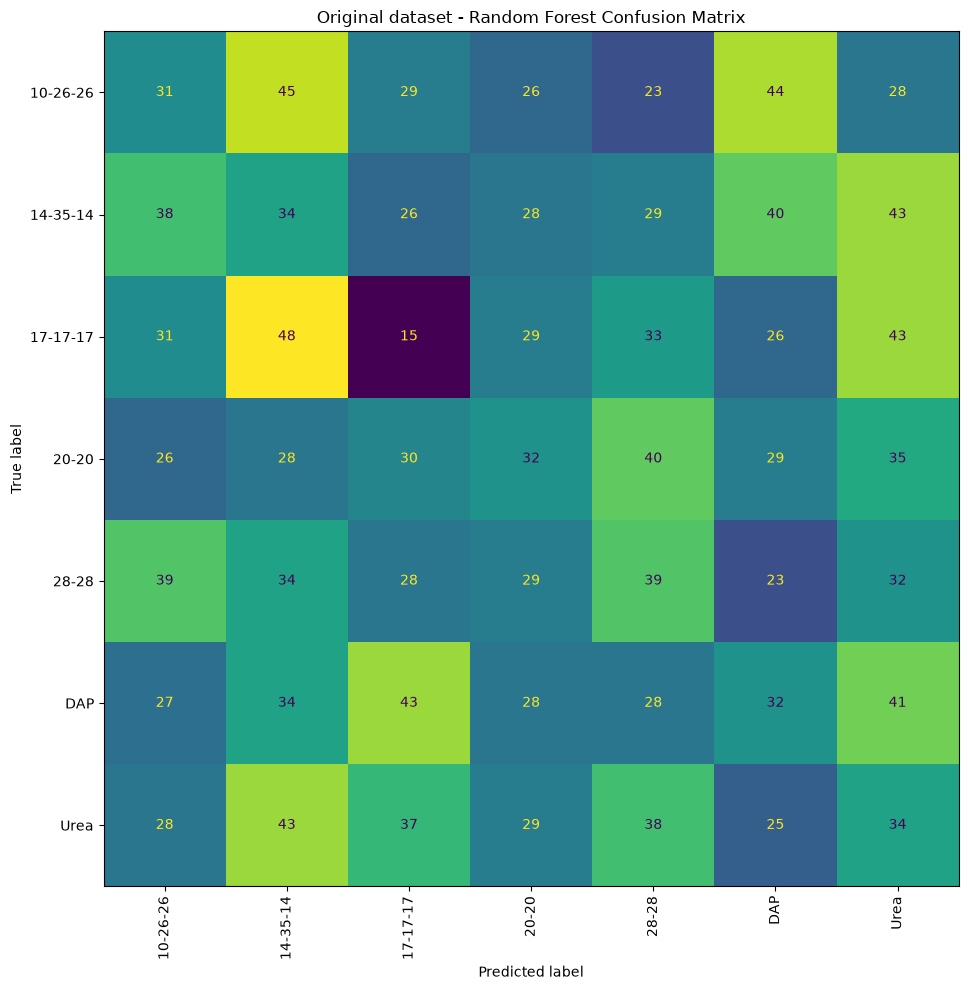

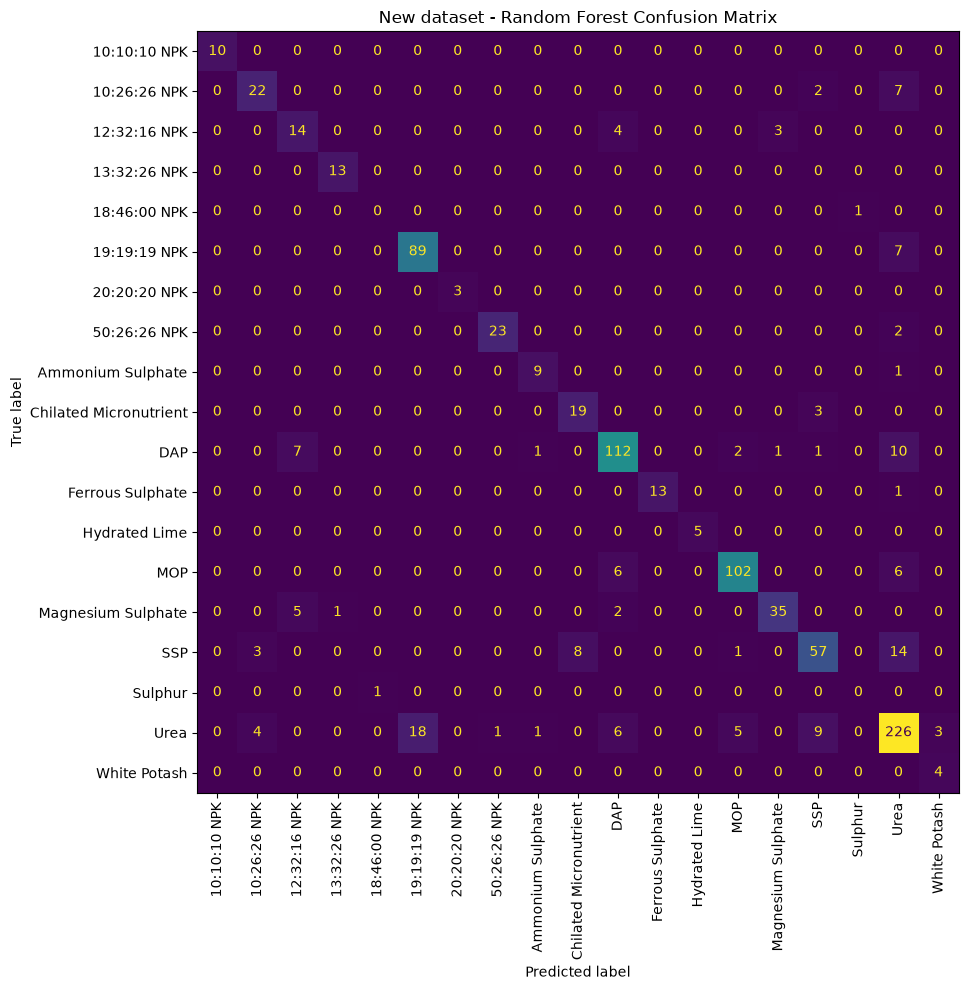

In [ ]:
# confusion matrices

def plot_confusion_matrix(
    name,
    y_test,
    predictions,
    mapping,
    filename,
):
    labels = mapping["Target_Label"].tolist()
    names = mapping["Fertilizer"].tolist()

    fig, ax = plt.subplots(figsize=(12, 10))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=labels,
        display_labels=names,
        xticks_rotation=90,
        ax=ax,
        colorbar=False,
    )

    ax.set_title(f"{name} - Random Forest Confusion Matrix")
    fig.tight_layout()
    fig.savefig(RESULT_DIR / filename, dpi=150)
    plt.show()

plot_confusion_matrix(
    "Original dataset",
    y_test_original,
    original_pred,
    original_mapping,
    "original_confusion_matrix.png",
)

plot_confusion_matrix(
    "New dataset",
    y_test_new,
    new_pred,
    new_mapping,
    "new_confusion_matrix.png",
)

#This code creates confusion matrices for both datasets to visualize the correct 
#and incorrect fertilizer predictions, and saves them as image files.”

,Feature,Importance
1,numeric__Humidity,0.138283
0,numeric__Temparature,0.138122
2,numeric__Moisture,0.136943
6,numeric__NPK_Imbalance,0.106632
3,numeric__Nitrogen,0.106254
5,numeric__Phosphorous,0.101440
4,numeric__Potassium,0.064961
11,categorical__Soil Type_Sandy,0.016316
9,categorical__Soil Type_Loamy,0.016246
10,categorical__Soil Type_Red,0.015259


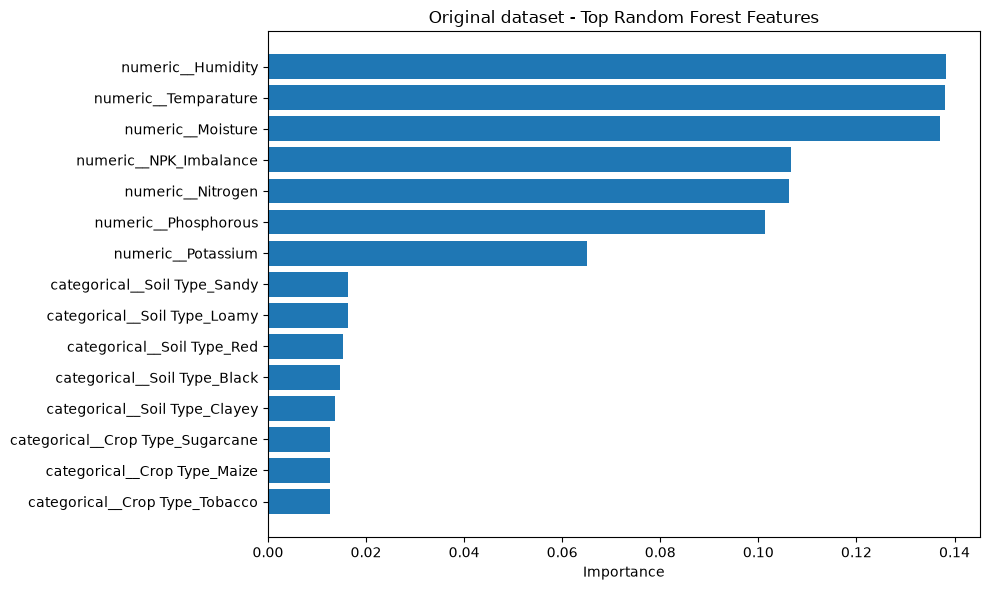

,Feature,Importance
1,numeric__Phosphorus,0.180357
2,numeric__Potassium,0.139895
6,numeric__NPK_Imbalance,0.109487
3,numeric__pH,0.090930
0,numeric__Nitrogen,0.082718
5,numeric__Temperature,0.081432
4,numeric__Rainfall,0.070804
34,categorical__Crop_Wheat,0.044596
19,categorical__Crop_Cotton,0.031956
23,categorical__Crop_Groundnut,0.017911


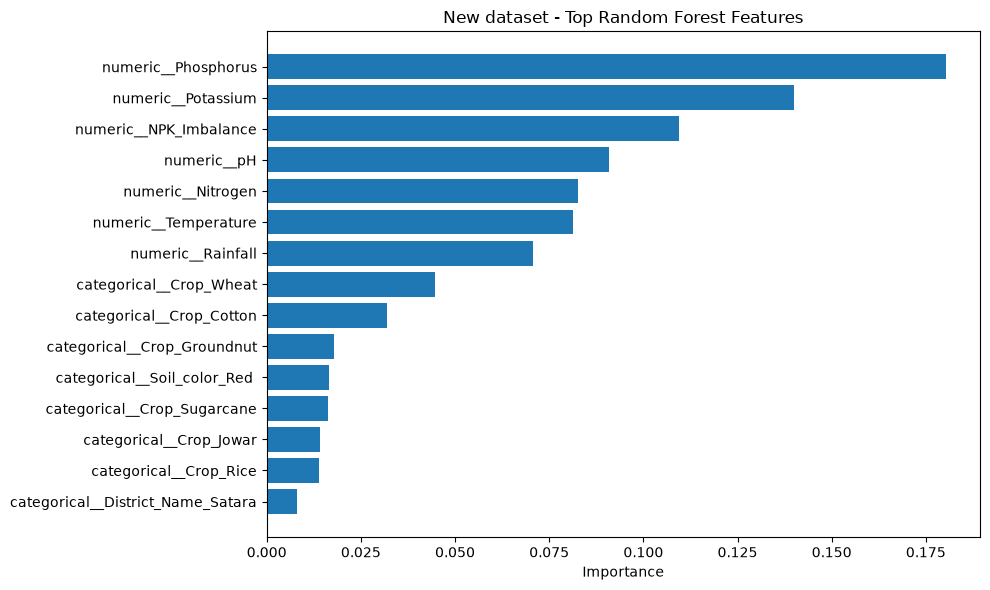

In [ ]:
# feature importance

def plot_feature_importance(
    name,
    model,
    feature_names,
    filename,
):
    importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": model.feature_importances_,
    }).sort_values(
        "Importance",
        ascending=False,
    )

    display(importance.head(15))

    importance.to_csv(
        RESULT_DIR / filename.replace(".png", ".csv"),
        index=False,
    )

    top = importance.head(15)

    plt.figure(figsize=(10, 6))
    plt.barh(
        top["Feature"][::-1],
        top["Importance"][::-1],
    )
    plt.title(f"{name} - Top Random Forest Features")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.savefig(
        RESULT_DIR / filename,
        dpi=150,
    )
    plt.show()

plot_feature_importance(
    "Original dataset",
    original_model,
    X_train_original.columns,
    "original_feature_importance.png",
)

plot_feature_importance(
    "New dataset",
    new_model,
    X_train_new.columns,
    "new_feature_importance.png",
)
#This code identifies and visualizes the most important features used by
# the Random Forest model to make fertilizer predictions.”

In [ ]:
# summary

for row in results.to_dict(orient="records"):
    print(f"\n{row['Dataset']} dataset")
    print(f"Baseline: {row['Majority_Baseline']:.4f}")
    print(f"Train accuracy: {row['Train_Accuracy']:.4f}")
    print(f"Test accuracy: {row['Test_Accuracy']:.4f}")
    print(f"Macro F1: {row['F1_Macro']:.4f}")
    print(f"Weighted F1: {row['F1_Weighted']:.4f}")
    print(f"5-fold CV accuracy: {row['CV_Accuracy_Mean']:.4f}")
    
→ #This code displays the main performance metrics of the Random 
#Forest model for each dataset, including baseline, train accuracy,
# test accuracy, F1 scores, and 5-fold cross-validation accuracy


Original dataset
Baseline: 0.1487
Train accuracy: 1.0000
Test accuracy: 0.1356
Macro F1: 0.1353
Weighted F1: 0.1353
5-fold CV accuracy: 0.1436

New dataset
Baseline: 0.3023
Train accuracy: 0.9994
Test accuracy: 0.8372
Macro F1: 0.7687
Weighted F1: 0.8375
5-fold CV accuracy: 0.8050


In [ ]:
# tuning

from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

def tune_model(
    dataset,
    estimator,
    param_grid,
    X_train,
    y_train,
    X_test,
    y_test,
):
    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
    )

    search.fit(X_train, y_train)

    model = search.best_estimator_
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    tuning_table = pd.DataFrame(search.cv_results_)[[
        "params",
        "mean_test_score",
        "std_test_score",
        "rank_test_score",
    ]].sort_values("rank_test_score")

    result = {
        "Dataset": dataset,
        "Variant": "Tuned",
        "Train_Accuracy": accuracy_score(y_train, train_pred),
        "Test_Accuracy": accuracy_score(y_test, test_pred),
        "Precision_Weighted": precision_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "Recall_Weighted": recall_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "F1_Weighted": f1_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "F1_Macro": f1_score(
            y_test,
            test_pred,
            average="macro",
            zero_division=0,
        ),
        "CV_Best_Macro_F1": search.best_score_,
        "Best_Params": str(search.best_params_),
    }

    return model, test_pred, tuning_table, result
    #“This code uses GridSearchCV with 5-fold stratified 
    #cross-validation to test different hyperparameter combinations
    #and select the best Random Forest model based on Macro F1 score.”


In [ ]:
# tune both datasets

param_grid = {
    "n_estimators": [200, 300],
    "max_depth": [20, None],
    "min_samples_leaf": [1, 2],
    "class_weight": [None, "balanced"],
}

original_tuned_model, original_tuned_pred, original_tuning, original_tuned_result = tune_model(
    "Original",
    RandomForestClassifier(random_state=42, n_jobs=1),
    param_grid,
    X_train_original,
    y_train_original,
    X_test_original,
    y_test_original,
)

new_tuned_model, new_tuned_pred, new_tuning, new_tuned_result = tune_model(
    "New",
    RandomForestClassifier(random_state=42, n_jobs=1),
    param_grid,
    X_train_new,
    y_train_new,
    X_test_new,
    y_test_new,
)

print("Original best parameters:")
print(original_tuned_result["Best_Params"])

print("\nNew best parameters:")
print(new_tuned_result["Best_Params"])

print("\nOriginal top configurations:")
display(original_tuning.head(5))

print("\nNew top configurations:")
display(new_tuning.head(5))
#This code tests different Random Forest hyperparameters using GridSearchCV
#and identifies the best configuration for the Original and New datasets.

In [ ]:
# tuning comparison

default_comparison = results[[
    "Dataset",
    "Train_Accuracy",
    "Test_Accuracy",
    "Precision_Weighted",
    "Recall_Weighted",
    "F1_Weighted",
    "F1_Macro",
]].copy()

default_comparison.insert(1, "Variant", "Default")
default_comparison["CV_Best_Macro_F1"] = pd.NA
default_comparison["Best_Params"] = "Default parameters"

tuned_comparison = pd.DataFrame([
    original_tuned_result,
    new_tuned_result,
])

comparison = pd.concat(
    [default_comparison, tuned_comparison],
    ignore_index=True,
)

display(comparison.round(4))

comparison.to_csv(
    RESULT_DIR / "random_forest_tuning_comparison.csv",
    index=False,
)

original_tuning.to_csv(
    RESULT_DIR / "original_tuning_results.csv",
    index=False,
)

new_tuning.to_csv(
    RESULT_DIR / "new_tuning_results.csv",
    index=False,
)
#This code combines the default and tuned Random Forest results
# into one comparison table and saves the results as CSV files.

In [ ]:
# tuned confusion matrices

plot_confusion_matrix(
    "Original dataset - tuned",
    y_test_original,
    original_tuned_pred,
    original_mapping,
    "original_tuned_confusion_matrix.png",
)

plot_confusion_matrix(
    "New dataset - tuned",
    y_test_new,
    new_tuned_pred,
    new_mapping,
    "new_tuned_confusion_matrix.png",
)
#This code generates confusion matrices for the tuned Random Forest models
#to show which fertilizer classes were predicted correctly and which were misclassified


In [ ]:
# tuned summary

for row in tuned_comparison.to_dict(orient="records"):
    print(f"\n{row['Dataset']} dataset")
    print(f"Best parameters: {row['Best_Params']}")
    print(f"Test accuracy: {row['Test_Accuracy']:.4f}")
    print(f"Weighted F1: {row['F1_Weighted']:.4f}")
    print(f"Macro F1: {row['F1_Macro']:.4f}")
    print(f"Best 5-fold CV macro F1: {row['CV_Best_Macro_F1']:.4f}")
    #This code displays the final performance of the tuned Random
    #Forest models, including the best parameters, test accuracy, 
    #weighted F1, macro F1, and the best 5-fold cross-validation macro F1 score.
